<!-- repo-header -->
# Scaling of the reweighting success probability (Haar-random segments)

Does Q-MERGE still work when the data is enormous? This notebook answers that by
replacing real data with **Haar-random** segments, which are the worst case: they
have no exploitable structure at all.

The justification for using them as a proxy is that shallow random brickwall
circuits converge quickly to Haar-random, so a Haar-random target is what
preconditioning approximates in the limit of zero optimisation effort. The resulting
success probability is therefore a reasonable *lower* bound on what preconditioning
achieves.

**Result.** P is independent of segment size N and decays only slowly in the number
of segments M, staying above 5% out to **M = 10^7** -- so the framework is not
limited by the number of segments in any practical regime.

Writes `sweep_success_prob_vs_M.csv` (paper Fig. 5), plus `_vs_N.csv` and
`_2D.csv` for the supporting sweeps, and `precond_vs_M.csv`.

Each sweep point is saved to CSV as soon as it finishes, so the notebook is safe to
interrupt and resume.


# Reweighting success probability vs. M and N (Haar-random test data)

**Goal:** empirically measure how the Stage-2 reweighting success probability
$P=1/\beta^2$ scales with $M$ (number of chunks/registers) and $N$ (chunk length),
using Haar-random chunks as generic test data (as opposed to the structured R75
ultrasound data used elsewhere in this project).

## What this notebook reuses vs. reimplements

Before writing anything, I searched the repo for existing Stage-1 / Stage-2 code.
Summary of what was found and what this notebook does with it:

| Piece | Existing location | What this notebook does |
|---|---|---|
| Stage-1 weighted-stack vector $\lvert\psi_\mathbf w\rangle$, $w_i=\prod_{k\neq i}(\psi_k)_{u_k}$ | `mre_prep.py::weighted_stack_vector` (verified, pure numpy — no circuit needed) | **Imported and used directly** as the ground-truth reference to validate this notebook's own per-branch weight computation. |
| Stage-1 measurement sampler ($\vec u$ from the true mixture distribution, Prop. 1 / Appendix E of the paper) | `mre_prep.py::sample_outcomes` (pure numpy, one-shot-at-a-time) | **Imported and used directly** for the single-trial walkthrough below. |
| Row weights $\sigma_i$ from a target array | `extract_row_weights` in `MainMREnotebook.ipynb` (cell 26) | **Ported verbatim** (it's already plain numpy, just lives in a notebook cell, not an importable module) into `generate_haar_target` below, applied to Haar-random Gaussian rows instead of the real R75 data. |
| Stage-2 success probability $P=\min_i(p_i/\sigma_i^2)=1/\beta^2$ | `reweight_success` in `MainMREnotebook.ipynb` (cell 27), and `block_encoding_success` in `SU4 Reweighting POC.ipynb` | **Reimplemented** in a numpy-vectorized batch form (`batch_reweighting_quantities` below) so thousands of trials can run without a Python loop per trial — validated below to agree with the exact `mre_prep.py`-based computation to floating-point precision (~1e-15 relative error) before being trusted for the sweep. |
| A "success probability vs. M/N" sweep | Only a partial, non-vectorized version exists (`Amplitude flattening/results.ipynb`, using a different normalized quantity $p_Q$, not this project's exact $\alpha_i/\beta/P$ definitions) | This notebook is a fresh, purpose-built, vectorized sweep using this project's exact Stage-2 definitions. |

No Qiskit circuit code (`mre_prep.build_compression_circuit`, the `.qpy` files) is used here — it implements the same Stage-1 math at the circuit level but would be far too slow for a parameter sweep over thousands of trials, so we go straight to the classical/analytic math it's built from.

In [2]:
import sys, os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, os.getcwd())
from mre_prep import weighted_stack_vector, sample_outcomes   # Stage-1, reused directly

RNG_SEED = 0
RED, BLUE, GREEN, GREY, BLACK = '#c0392b', '#2c5aa0', '#1f7a3f', '#7f8c8d', '#111111'
LINE_COLORS = [BLUE, RED, GREEN, GREY, BLACK]   # fixed categorical order for multi-line plots

## 1. Definitions (Stages 1 and 2, following the paper)

**Stage 1 — weighted stack.** We split a target state into $M$ normalised chunks
$\{\lvert\psi_i\rangle\in\mathbb C^N\}$ with weights $\sigma_i$ ($\sum_i\sigma_i^2=1$).
After the SELECT-SWAP compression circuit measures all $M$ preparation registers and
gets outcome $\vec u=(u_0,\dots,u_{M-1})$, the surviving state is the *weighted stack*
$$\lvert\psi_\mathbf w\rangle=\frac{1}{\sqrt{\mathcal N}}\sum_i w_i\lvert\psi_i\rangle\lvert i\rangle,
\qquad w_i=\prod_{k\neq i}(\psi_k)_{u_k}, \qquad \mathcal N=\sum_i\lvert w_i\rvert^2.$$

**Stage 2 — reweighting.** A diagonal block encoding restores the original weights
$\sigma_i$, succeeding (ancilla measured $\lvert0\rangle$) with probability
$$\alpha_i=\sqrt{\mathcal N}\,\frac{\sigma_i}{w_i}, \qquad
\beta=\max_i\lvert\alpha_i\rvert, \qquad
P=\frac{1}{\beta^2}.$$

This matches what the repo's own `reweight_success`/`block_encoding_success` functions
already compute ($P=\min_i(p_i/\sigma_i^2)$) — cross-checked against `mre_prep.py`'s
`weighted_stack_vector` below before trusting it for the sweep.

## 2. Haar-random test data

We sample $M$ independent Haar-random pure states of dimension $N$ by drawing
independent complex Gaussian vectors and normalising (the standard construction —
row $\times$ column entries iid $\mathcal{CN}(0,1)$, then unit-normalise each row).
The chunk weights $\sigma_i$ are then taken from the *same* Gaussian draw's row
norms, exactly the way `extract_row_weights` derives $\sigma_i$ from a real target
array — i.e. the "target state" being chopped up is itself just the full $MN$-dim
Gaussian vector, and $\sigma_i$ is its natural row-norm partition.

In [3]:
def generate_haar_target(M, N, rng):
    '''One trial's worth of target data: M Haar-random chunks of dim N, and their
    weights sigma_i (ported from extract_row_weights, MainMREnotebook.ipynb cell 26).'''
    raw = rng.standard_normal((M, N)) + 1j * rng.standard_normal((M, N))
    row_norms = np.linalg.norm(raw, axis=1)
    total = np.linalg.norm(row_norms)
    sigma = row_norms / total              # sum(sigma**2) == 1
    chunks = raw / row_norms[:, None]      # each row unit-norm (Haar-random state)
    return chunks, sigma


def compute_reweighting_quantities(chunks, sigma, u):
    '''Explicit, single-trial Stage-2 walkthrough: w_i -> N_norm -> alpha_i -> beta -> P.

    |w_i| is a product of up to M-1 numbers, so |w_i|^2 can underflow to exactly 0.0
    once M gets large (np.exp underflows below about -745) -- and since EVERY branch
    underflows together, that turns N_norm = sum|w_i|^2 into 0/0 = nan across the
    board. To stay safe at any M, N_norm/alpha_i/beta/P are computed with a
    logsumexp-stabilised log-space calculation (only ever exponentiating small,
    well-behaved log-differences); only the raw |w_i| array kept for the printed
    walkthrough below can itself underflow at extreme M -- that's fine, it's just
    for display, and doesn't feed into the P calculation.'''
    M, N = chunks.shape
    amp = chunks[np.arange(M), u]                 # (psi_k)_{u_k} for every k
    log_abs_amp = np.log(np.abs(amp))
    total_log = log_abs_amp.sum()
    log_abs_w = total_log - log_abs_amp            # leave-one-out: log|w_i| = sum_{k!=i} log|amp_k|
    abs_w = np.exp(log_abs_w)                      # |w_i|, i = 0..M-1 (display only, can underflow)

    log_2w = 2 * log_abs_w                          # log|w_i|^2
    m = np.max(log_2w)                               # logsumexp stabiliser
    log_N_norm = m + np.log(np.sum(np.exp(log_2w - m)))            # log(mathcal N), never underflows
    log_alpha2 = log_N_norm + 2 * np.log(sigma) - log_2w            # log|alpha_i|^2
    log_beta2 = np.max(log_alpha2)

    N_norm = float(np.exp(log_N_norm)) if log_N_norm > -700 else 0.0   # for display; may legitimately underflow
    beta = float(np.exp(0.5 * log_beta2))
    P = float(np.exp(-log_beta2))                                 # P = 1/beta^2, always in [0,1]
    return {"abs_w": abs_w, "N_norm": N_norm, "beta": beta, "P": P}

In [4]:
# --- one illustrative trial, walked through step by step ---
rng = np.random.default_rng(RNG_SEED)
M_demo, N_demo = 6, 20

chunks, sigma = generate_haar_target(M_demo, N_demo, rng)
u = np.array(sample_outcomes(chunks, n_samples=1, seed=int(rng.integers(1e9)))[0])   # Stage-1 measurement (mre_prep.py)

q = compute_reweighting_quantities(chunks, sigma, u)

print(f"M={M_demo}, N={N_demo}")
print(f"sigma        = {np.round(sigma, 4)}")
print(f"u (measured) = {u}")
print(f"|w_i|        = {np.round(q['abs_w'], 6)}")
print(f"N_norm       = {q['N_norm']:.6e}")
print(f"beta         = {q['beta']:.4f}")
print(f"P            = {q['P']:.6f}")

# cross-check against mre_prep.py's own weighted_stack_vector, independently
psi_w = weighted_stack_vector(chunks, u)
p_i = np.sum(np.abs(psi_w.reshape(M_demo, N_demo)) ** 2, axis=1)   # block probabilities
P_from_mre_prep = np.min(p_i / sigma ** 2)
print(f"\nP (from mre_prep.weighted_stack_vector) = {P_from_mre_prep:.6f}")
print(f"relative difference                       = {abs(P_from_mre_prep - q['P']) / q['P']:.2e}")
assert abs(P_from_mre_prep - q["P"]) / q["P"] < 1e-8

M=6, N=20
sigma        = [0.3897 0.3296 0.4197 0.4207 0.422  0.4564]
u (measured) = [12 15  0 15 19  0]
|w_i|        = [0.000716 0.000933 0.001335 0.000863 0.000541 0.00388 ]
N_norm       = 1.925513e-05
beta         = 3.4214
P            = 0.085425

P (from mre_prep.weighted_stack_vector) = 0.085425
relative difference                       = 3.25e-16


## 3. Vectorized batch machinery (for the sweep)

`compute_reweighting_quantities` above is exact and matches `mre_prep.py`, but it's a
Python function called once per trial. For a sweep with thousands of trials per
$(M,N)$ point, we need a numpy-vectorized version that processes a whole batch of
independent trials at once (batch axis $B$), while never materialising a full
`(n_trials, M, N)` array for the *entire* sweep — we process one modest batch at a
time and only keep the resulting scalar $P$ values.

`batch_sample_outcomes` below is a vectorized port of `mre_prep.sample_outcomes`'s
exact sampling recipe (pick a uniformly-random "spectator" register per trial;
sample it uniformly; sample every other register from its own Born distribution
$\lvert\psi_k\rvert^2$ via inverse-CDF sampling) — same algorithm, just batched with
numpy broadcasting instead of a per-trial Python loop.

In [5]:
def batch_generate_haar_targets(B, M, N, rng):
    '''Batched version of generate_haar_target: B independent trials at once.'''
    raw = rng.standard_normal((B, M, N)) + 1j * rng.standard_normal((B, M, N))
    row_norms = np.linalg.norm(raw, axis=2)             # (B,M)
    total = np.linalg.norm(row_norms, axis=1)             # (B,)
    sigma = row_norms / total[:, None]                     # (B,M)
    chunks = raw / row_norms[:, :, None]                   # (B,M,N)
    return chunks, sigma


def batch_sample_outcomes(chunks, rng):
    '''Vectorized port of mre_prep.sample_outcomes's sampling recipe (Prop. 1):
    one uniformly-random spectator register per trial (sampled uniformly), every
    other register sampled from its own Born distribution |psi_k|^2.'''
    B, M, N = chunks.shape
    born = np.abs(chunks) ** 2                             # (B,M,N), each row already sums to 1
    cdf = np.cumsum(born, axis=-1)
    cdf[..., -1] = 1.0                                       # guard against float round-off
    r = rng.random((B, M))
    u_born = np.argmax(cdf >= r[..., None], axis=-1)        # inverse-CDF (Born) sample per register
    u_uniform = rng.integers(0, N, size=(B, M))
    spectator = rng.integers(0, M, size=B)
    is_spectator = (np.arange(M)[None, :] == spectator[:, None])
    u = np.where(is_spectator, u_uniform, u_born)
    return u, born


def batch_reweighting_quantities(chunks, sigma, u, born):
    '''Batched version of compute_reweighting_quantities.

    BUG FIX: the first version of this function computed |w_i|^2 = np.exp(2*log_abs_w)
    directly. Once M got large enough that 2*log_abs_w < ~-745, exp() underflowed to
    exactly 0.0 for EVERY branch in a trial simultaneously (since all M branches have
    comparably tiny |w_i| at large M), turning N_norm = sum|w_i|^2 into 0, and
    alpha2 = N_norm*sigma^2/abs_w2 into 0/0 = nan for the entire batch -- which then
    crashed summarize()'s percentile call on an all-nan-filtered, zero-length array.
    Fixed the same way as compute_reweighting_quantities: do the N_norm/alpha/beta/P
    arithmetic entirely in log-space via a logsumexp (only ever exponentiating small,
    well-behaved log-differences), so P stays finite and in [0,1] at any M
    (validated up to M=1000 -- see the validation cell below).'''
    B, M, N = chunks.shape
    abs_amp = np.sqrt(np.take_along_axis(born, u[..., None], axis=-1)[..., 0])   # (B,M)
    log_abs_amp = np.log(abs_amp)
    total_log = log_abs_amp.sum(axis=-1, keepdims=True)
    log_abs_w = total_log - log_abs_amp                        # (B,M), log|w_i|

    log_2w = 2 * log_abs_w                                      # log|w_i|^2
    m = np.max(log_2w, axis=-1, keepdims=True)                   # per-trial logsumexp stabiliser
    log_N_norm = m[..., 0] + np.log(np.sum(np.exp(log_2w - m), axis=-1))   # (B,) log(mathcal N)

    log_sigma2 = 2 * np.log(sigma)                                 # (B,M)
    log_alpha2 = log_N_norm[:, None] + log_sigma2 - log_2w          # (B,M)  log|alpha_i|^2
    log_beta2 = np.max(log_alpha2, axis=-1)                         # (B,)

    P = np.exp(-log_beta2)                                           # always finite, in [0,1]
    with np.errstate(under='ignore'):
        N_norm = np.exp(log_N_norm)                                    # can legitimately underflow to 0 at large M
    beta2 = np.exp(log_beta2)
    return P, N_norm, beta2

In [6]:
# --- validate the batch path against the single-trial path (which itself matches mre_prep.py) ---
rng_check = np.random.default_rng(123)
B_check, M_check, N_check = 50, 8, 30
chunks_b, sigma_b = batch_generate_haar_targets(B_check, M_check, N_check, rng_check)
u_b, born_b = batch_sample_outcomes(chunks_b, rng_check)
P_b, Nn_b, beta2_b = batch_reweighting_quantities(chunks_b, sigma_b, u_b, born_b)

max_rel_err = 0.0
for b in range(B_check):
    q_b = compute_reweighting_quantities(chunks_b[b], sigma_b[b], u_b[b])
    max_rel_err = max(max_rel_err, abs(q_b["P"] - P_b[b]) / q_b["P"])
print(f"batch vs. single-trial path: max relative error over {B_check} trials = {max_rel_err:.2e}")
assert max_rel_err < 1e-8, "batched implementation disagrees with the validated single-trial path"
print("OK -- batched implementation matches the mre_prep.py-validated single-trial path.")

# also check the large-M regime that originally broke the naive (non-log-space) version:
# exp(2*log|w_i|) underflows to exactly 0 once M is large enough, which used to turn
# N_norm into 0 and alpha^2 into 0/0 = nan for an entire batch. Confirm P now
# stays finite and in [0,1] well past that point.
rng_big = np.random.default_rng(0)
for M_big, N_big in [(200, 64), (500, 64), (1000, 32)]:
    chunks_big, sigma_big = batch_generate_haar_targets(50, M_big, N_big, rng_big)
    u_big, born_big = batch_sample_outcomes(chunks_big, rng_big)
    P_big, Nn_big, beta2_big = batch_reweighting_quantities(chunks_big, sigma_big, u_big, born_big)
    ok = np.isfinite(P_big).all() and (P_big >= 0).all() and (P_big <= 1).all()
    print(f"  M={M_big:5d} N={N_big:4d}: P finite & in [0,1]? {ok}   "
          f"mean P = {P_big.mean():.4f}")
    assert ok, f"P should always be finite and in [0,1] (failed at M={M_big}, N={N_big})"
print("OK -- large-M underflow bug is fixed; P stays well-behaved up to M=1000.")

batch vs. single-trial path: max relative error over 50 trials = 0.00e+00
OK -- batched implementation matches the mre_prep.py-validated single-trial path.
  M=  200 N=  64: P finite & in [0,1]? True   mean P = 0.1260
  M=  500 N=  64: P finite & in [0,1]? True   mean P = 0.1136
  M= 1000 N=  32: P finite & in [0,1]? True   mean P = 0.1081
OK -- large-M underflow bug is fixed; P stays well-behaved up to M=1000.


## 4. Sweep orchestration (memory-conscious batching)

For a given $(M,N)$, `run_trials_for_MN` runs `n_trials` total, split into batches of
`batch_size` so that the largest array in memory at any time is `(batch_size, M, N)`
complex128 rather than `(n_trials, M, N)`. Only the resulting per-trial scalar $P$
values (a tiny `(n_trials,)` float array) are kept between batches; the batch's
`(batch_size, M, N)` chunk array is discarded once its batch is processed.

In [7]:
def choose_batch_size(M, N, target_bytes=5e7, cap=500):
    '''Batch size such that a (batch, M, N) complex128 array stays under ~target_bytes.'''
    bytes_per_trial = M * N * 16   # complex128 = 16 bytes
    return int(max(1, min(cap, target_bytes // bytes_per_trial)))


def summarize(P):
    '''Mean/median/percentiles/min/max of an array of per-trial success probabilities,
    ignoring any non-finite values (and reporting how many, if there are any).
    Defensive: if EVERY value in a batch is non-finite (shouldn't happen after the
    log-space fix above, but a grid point extreme enough to break float64's log range
    -- roughly M or N beyond ~1e300 in log-product terms -- is still conceivable), this
    returns NaN stats with a printed warning instead of crashing the whole sweep.'''
    finite = np.isfinite(P)
    n_bad = int((~finite).sum())
    Pf = P[finite]
    if len(Pf) == 0:
        print(f"  WARNING: all {len(P)} trials were non-finite for this (M,N) -- returning NaN stats.")
        return {"n_trials": len(P), "n_nonfinite": n_bad,
                "mean": np.nan, "median": np.nan, "p10": np.nan, "p90": np.nan,
                "min": np.nan, "max": np.nan}
    return {
        "n_trials": len(P), "n_nonfinite": n_bad,
        "mean": float(Pf.mean()), "median": float(np.median(Pf)),
        "p10": float(np.percentile(Pf, 10)), "p90": float(np.percentile(Pf, 90)),
        "min": float(Pf.min()), "max": float(Pf.max()),
    }


def run_trials_for_MN(M, N, n_trials, rng, batch_size=None, verbose=True):
    '''Run n_trials independent (fresh Haar target + fresh Stage-1 measurement) trials
    at fixed (M, N), in batches, and return summary stats for P.'''
    if batch_size is None:
        batch_size = choose_batch_size(M, N)
    P_all = []
    done = 0
    while done < n_trials:
        b = min(batch_size, n_trials - done)
        chunks, sigma = batch_generate_haar_targets(b, M, N, rng)
        u, born = batch_sample_outcomes(chunks, rng)
        P, N_norm, beta2 = batch_reweighting_quantities(chunks, sigma, u, born)
        P_all.append(P)
        done += b
    P_all = np.concatenate(P_all)
    if verbose:
        print(f"  M={M:3d} N={N:4d}  ({n_trials} trials, batch_size={batch_size}) done")
    stats = summarize(P_all)
    return {"M": M, "N": N, **{f"P_{k}": v for k, v in stats.items()}}

## 5. Sweep 1: success probability vs. $M$ (fixed $N$)

In [20]:
import os

CSV_PATH = "sweep_success_prob_vs_M.csv"

rng_sweep1 = np.random.default_rng(RNG_SEED + 1)
M_grid = [2, 3, 4, 6, 8, 10, 12, 16, 20, 24, 28, 32, 40, 100, 1000, 10000]
N_values_1 = [16, 64,128]
N_TRIALS_1 = 1500

# load whatever's already been computed, so reruns skip finished (M, N) points
if os.path.exists(CSV_PATH):
    df_M = pd.read_csv(CSV_PATH)
    done = set(zip(df_M["M"], df_M["N"]))
else:
    df_M = pd.DataFrame()
    done = set()

rows_M = df_M.to_dict("records")
t0 = time.time()
for N in N_values_1:
    print(f"N = {N}:")
    for M in M_grid:
        if (M, N) in done:
            print(f"  M={M}: already done, skipping")
            continue
        row = run_trials_for_MN(M, N, N_TRIALS_1, rng_sweep1)
        rows_M.append(row)
        done.add((M, N))
        pd.DataFrame(rows_M).to_csv(CSV_PATH, index=False)   # saved after every single point
        print(f"  M={M}: done  ({time.time()-t0:.1f}s elapsed)")

df_M = pd.DataFrame(rows_M)
print(f"\nsweep done in {time.time()-t0:.1f}s, {len(df_M)} (M,N) points total")
df_M.head()


N = 16:
  M=2: already done, skipping
  M=3: already done, skipping
  M=4: already done, skipping
  M=6: already done, skipping
  M=8: already done, skipping
  M=10: already done, skipping
  M=12: already done, skipping
  M=16: already done, skipping
  M=20: already done, skipping
  M=24: already done, skipping
  M=28: already done, skipping
  M=32: already done, skipping
  M=40: already done, skipping
  M=100: already done, skipping
  M=1000: already done, skipping
  M=10000: already done, skipping
N = 64:
  M=2: already done, skipping
  M=3: already done, skipping
  M=4: already done, skipping
  M=6: already done, skipping
  M=8: already done, skipping
  M=10: already done, skipping
  M=12: already done, skipping
  M=16: already done, skipping
  M=20: already done, skipping
  M=24: already done, skipping
  M=28: already done, skipping
  M=32: already done, skipping
  M=40: already done, skipping
  M=100: already done, skipping
  M=1000: already done, skipping
  M=10000: already done,

,M,N,P_n_trials,P_n_nonfinite,P_mean,P_median,P_p10,P_p90,P_min,P_max
0,2,16,1500,0,0.529086,0.542555,0.132058,0.906801,0.000548,0.999904
1,3,16,1500,0,0.397566,0.377533,0.094045,0.730219,0.000503,0.981040
2,4,16,1500,0,0.350363,0.326985,0.101746,0.634679,0.001160,0.890079
3,6,16,1500,0,0.302877,0.283918,0.094408,0.529398,0.000083,0.874026
4,8,16,1500,0,0.273595,0.259447,0.109981,0.452887,0.000182,0.832667


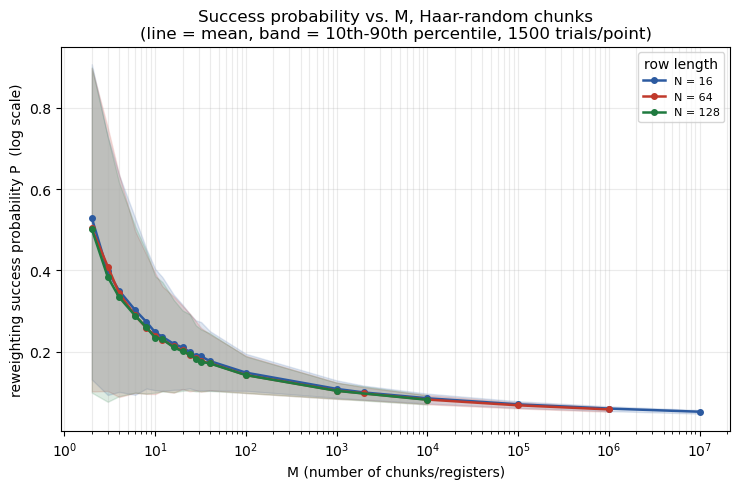


     N   M (largest tested)     P_mean      P_p10      P_p90
    16             10000000 5.2992e-02 4.8258e-02 5.7075e-02
    64              1000000 5.8703e-02 5.2906e-02 6.4016e-02
   128                10000 8.2335e-02 7.0767e-02 9.3462e-02

full sweep results:
       M   N  P_n_trials  P_n_nonfinite   P_mean  P_median    P_p10    P_p90    P_min    P_max
       2  16        1500              0 0.529086  0.542555 0.132058 0.906801 0.000548 0.999904
       3  16        1500              0 0.397566  0.377533 0.094045 0.730219 0.000503 0.981040
       4  16        1500              0 0.350363  0.326985 0.101746 0.634679 0.001160 0.890079
       6  16        1500              0 0.302877  0.283918 0.094408 0.529398 0.000083 0.874026
       8  16        1500              0 0.273595  0.259447 0.109981 0.452887 0.000182 0.832667
      10  16        1500              0 0.247871  0.239583 0.105632 0.403772 0.002513 0.626068
      12  16        1500              0 0.237142  0.231712 0.104110 0

In [23]:
import numpy as np

def theory_curve(M):
    '''Asymptotic prediction P ~ 1/(ln M + ln ln M), no free constant.'''
    lnM = np.log(M)
    return 1.0 / (lnM + np.log(lnM))

M_arr = df_M["M"].to_numpy(dtype=float)
valid_M = M_arr[M_arr > 2]   # need ln(ln M) finite
M_grid = np.logspace(np.log10(valid_M.min()), np.log10(valid_M.max()), 200)

fig, ax = plt.subplots(figsize=(7.5, 5))
for N, color in zip(N_values_1, LINE_COLORS):
    sub = df_M[df_M.N == N].sort_values("M")
    ax.plot(sub.M, sub.P_mean, color=color, marker='o', ms=4, lw=1.8, label=f"N = {N}")
    ax.fill_between(sub.M, sub.P_p10, sub.P_p90, color=color, alpha=0.15)

#ax.plot(M_grid, theory_curve(M_grid), color="black", ls="--", lw=2,
        #label="1 / (ln M + ln ln M)")

#ax.set_yscale('log')
ax.set_xscale("log")
ax.set_xlabel("M (number of chunks/registers)")
ax.set_ylabel("reweighting success probability P  (log scale)")
ax.set_title("Success probability vs. M, Haar-random chunks\n(line = mean, band = 10th-90th percentile, "
             f"{N_TRIALS_1} trials/point)")
ax.legend(title="row length", fontsize=8)
ax.grid(alpha=0.25, which='both')
plt.tight_layout(); plt.savefig("sweep_P_vs_M.png", dpi=130); plt.show()

print(f"\n{'N':>6s} {'M (largest tested)':>20s} {'P_mean':>10s} {'P_p10':>10s} {'P_p90':>10s}")
for N in N_values_1:
    sub = df_M[df_M.N == N].sort_values("M")
    last = sub.iloc[-1]
    print(f"{N:>6d} {int(last.M):>20d} {last.P_mean:>10.4e} {last.P_p10:>10.4e} {last.P_p90:>10.4e}")

print(f"\nfull sweep results:")
print(df_M.sort_values(["N", "M"]).to_string(index=False))


## Boosting success probability with classical pre-conditioning

In [24]:
import sys, torch
sys.path.insert(0, os.getcwd())
import quimb.tensor as qtn
from quimb.tensor import PTensor
from sso_framework_setup import su4_matrix, dense_state_from_op_mps, contract_layer_to_mps

def extract_row_weights(Y):
    rows = np.asarray(Y).T
    row_norms = np.linalg.norm(rows, axis=1); total = np.linalg.norm(row_norms)
    return row_norms / total, rows / row_norms[:, None]

def collapse_once_simple(chunks, seed=None):
    rng = np.random.default_rng(seed)
    M, N = chunks.shape
    spectator = rng.integers(M)
    u = np.zeros(M, dtype=int)
    for k in range(M):
        if k == spectator: u[k] = rng.integers(N)
        else:
            born = np.abs(chunks[k]) ** 2; u[k] = rng.choice(N, p=born / born.sum())
    amp = np.array([chunks[k, u[k]] for k in range(M)]); t = np.abs(amp) ** 2
    if np.all(t > 0):
        inv = 1.0 / t; p = inv / inv.sum()
    else:
        p = np.zeros(M); zero = (t == 0)
        if zero.sum() == 1: p[np.argmax(zero)] = 1.0
    return {"p": p}

def success_distribution(chunks, sigma, n_shots=3000, seed=0):
    rng = np.random.default_rng(seed); seeds = rng.integers(0, 2**31 - 1, size=n_shots)
    P = np.empty(n_shots)
    for s in range(n_shots):
        out = collapse_once_simple(chunks, seed=int(seeds[s]))
        with np.errstate(divide="ignore", invalid="ignore"):
            P[s] = np.min(out["p"] / sigma ** 2)
    return {"mean": P.mean()}


def make_brick_wall_layer(n, eps=0.0, seed=None):
    if seed is not None: torch.manual_seed(seed)
    def _init(m):
        p = torch.zeros(m, dtype=torch.float64)
        if eps > 0: p = p + eps * torch.randn(m, dtype=torch.float64)
        return p.requires_grad_(True)
    tensors = []
    def sublayer(in_prefix, out_prefix, pairs, untouched):
        for (q0, q1) in pairs:
            tensors.append(PTensor(su4_matrix, _init(15),
                                   inds=(f"{in_prefix}{q0}", f"{in_prefix}{q1}", f"{out_prefix}{q0}", f"{out_prefix}{q1}"),
                                   tags={"SU4"}))
        for q in untouched:
            tensors.append(qtn.Tensor(torch.eye(2, dtype=torch.complex128),
                                      inds=(f"{in_prefix}{q}", f"{out_prefix}{q}"), tags={"ID"}))
    even_pairs = [(i, i + 1) for i in range(0, n - 1, 2)]
    even_untouched = [q for q in range(n) if q not in {x for p in even_pairs for x in p}]
    sublayer("k", "mid", even_pairs, even_untouched)
    odd_pairs = [(i, i + 1) for i in range(1, n - 1, 2)]
    odd_untouched = [q for q in range(n) if q not in {x for p in odd_pairs for x in p}]
    sublayer("mid", "b", odd_pairs, odd_untouched)
    return qtn.TensorNetwork(tensors)


def optimise_flatten_layers_hybrid(mps, max_layers, layer_builder=make_brick_wall_layer,
                                    n_iter=200, eps_init=1e-2, seed=0, tol=1e-14, verbose=False,
                                    plateau_rel_tol=1e-3, plateau_patience=2):
    n = mps.L
    def ipr_of_op(op, target_mps):
        psi = dense_state_from_op_mps(op, target_mps).reshape(-1)
        psi = psi / torch.sqrt((psi.conj() * psi).sum().real)
        return (torch.abs(psi) ** 4).sum()
    def optimise_stack(stack_init, target_mps, n_iter_):
        best = {"val": float("inf"), "params": None}
        def loss(op, init_tn):
            val = ipr_of_op(op, init_tn); s = float(val.detach())
            if s < best["val"]:
                best["val"] = s
                best["params"] = {k: vv.detach().cpu().numpy().copy() for k, vv in op.get_params().items()}
            return val
        qtn.TNOptimizer(stack_init, loss, loss_constants={"init_tn": target_mps}, optimizer="l-bfgs-b",
                        autodiff_backend="torch", progbar=verbose).optimize(n=n_iter_, tol=tol)
        if best["params"] is not None:
            stack_init.set_params({k: torch.as_tensor(v) for k, v in best["params"].items()})
            return stack_init, best["val"]
        return stack_init, float(ipr_of_op(stack_init, target_mps).detach())

    mps = mps.copy(); mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
    current_mps = mps.copy()
    psi0 = np.asarray(current_mps.to_dense()).reshape(-1); psi0 /= np.linalg.norm(psi0)
    per_layer_ipr = [float(np.sum(np.abs(psi0) ** 4))]
    per_layer_psi = [psi0]
    stack = None
    stall_count = 0
    stopped_at = max_layers
    for L in range(max_layers):
        new_layer = layer_builder(n, eps=eps_init, seed=seed + L)
        new_layer, _ = optimise_stack(new_layer, current_mps, n_iter)
        inner = [ix for ix in new_layer.all_inds() if ix not in new_layer.outer_inds()]
        new_layer = new_layer.copy(); new_layer.reindex_({ix: f"L{L}_{ix}" for ix in inner})
        if stack is None:
            candidate = new_layer
        else:
            mid = f"grow{L}_"
            base = stack.copy(); base.reindex_({f"b{i}": f"{mid}{i}" for i in range(n)})
            nl = new_layer.copy(); nl.reindex_({f"k{i}": f"{mid}{i}" for i in range(n)})
            candidate = qtn.TensorNetwork(list(base.tensors) + list(nl.tensors))
        candidate, ipr_joint = optimise_stack(candidate, mps, n_iter)
        prev_ipr = per_layer_ipr[-1]
        if ipr_joint <= prev_ipr:
            stack = candidate; accepted_ipr = ipr_joint
            current_mps = contract_layer_to_mps(stack, mps)
        else:
            accepted_ipr = prev_ipr
        psi_now = np.asarray(current_mps.to_dense()).reshape(-1); psi_now /= np.linalg.norm(psi_now)
        per_layer_ipr.append(accepted_ipr); per_layer_psi.append(psi_now)
        rel_improve = (prev_ipr - accepted_ipr) / prev_ipr if prev_ipr > 0 else 0.0
        stall_count = stall_count + 1 if rel_improve < plateau_rel_tol else 0
        if verbose:
            print(f"    layer {L+1}/{max_layers}: IPR {prev_ipr:.4e} -> {accepted_ipr:.4e}  stall={stall_count}")
        if stall_count >= plateau_patience:
            stopped_at = L + 1 - (plateau_patience - 1)
            while len(per_layer_ipr) <= max_layers:
                per_layer_ipr.append(per_layer_ipr[-1]); per_layer_psi.append(per_layer_psi[-1])
            break
    return {"per_layer_ipr": per_layer_ipr, "per_layer_psi": per_layer_psi, "stopped_at": stopped_at}


# ============================================================
# Preconditioning test: for N=64 fixed, small M, one Haar-random
# target each, trained up to 10 brick-wall layers -- see how far M can go.
# ============================================================
PRECOND_N = 64
PRECOND_M_LIST = [2, 4, 8, 16, 32, 64]   # extend this (128, 256, ...) as far as it stays fast enough
PRECOND_MAX_LAYERS = 10
PRECOND_SAVE_PATH = "precond_vs_M.csv"

if os.path.exists(PRECOND_SAVE_PATH):
    precond_df = pd.read_csv(PRECOND_SAVE_PATH)
    done_M = set(precond_df["M"])
else:
    precond_df = pd.DataFrame()
    done_M = set()

rows_precond = precond_df.to_dict("records")
for M in PRECOND_M_LIST:
    if M in done_M:
        print(f"M={M}: already done, skipping")
        continue
    n_qubits = int(round(np.log2(M * PRECOND_N)))
    if 2 ** n_qubits != M * PRECOND_N:
        print(f"M={M}: M*N={M*PRECOND_N} is not a power of 2, skipping (need M to be a power of 2 given N=64)")
        continue

    t0 = time.time()
    rng_m = np.random.default_rng(RNG_SEED + M)
    raw = rng_m.standard_normal((PRECOND_N, M)) + 1j * rng_m.standard_normal((PRECOND_N, M))
    Y = raw / np.linalg.norm(raw)

    sigma0, chunks0 = extract_row_weights(Y)
    res_base = success_distribution(chunks0, sigma0, n_shots=3000, seed=RNG_SEED)

    v = Y.astype(np.complex128).T.flatten(); v /= np.linalg.norm(v)
    mps = qtn.MatrixProductState.from_dense(v.reshape([2] * n_qubits), dims=[2] * n_qubits)
    mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))

    seq = optimise_flatten_layers_hybrid(mps, PRECOND_MAX_LAYERS, seed=RNG_SEED, verbose=True)
    psi_final = seq["per_layer_psi"][-1]
    Y_final = psi_final.reshape(M, PRECOND_N).T
    sigmaF, chunksF = extract_row_weights(Y_final)
    res_final = success_distribution(chunksF, sigmaF, n_shots=3000, seed=RNG_SEED)

    row = {"M": M, "N": PRECOND_N, "n_qubits": n_qubits, "layers_used": seq["stopped_at"],
           "P_baseline": res_base["mean"], "P_preconditioned": res_final["mean"],
           "final_ipr": seq["per_layer_ipr"][-1], "time_s": time.time() - t0}
    rows_precond.append(row)
    pd.DataFrame(rows_precond).to_csv(PRECOND_SAVE_PATH, index=False)   # saved after every M
    print(f"M={M:4d} ({n_qubits} qubits): P {row['P_baseline']:.4f} -> {row['P_preconditioned']:.4f}  "
          f"({row['P_preconditioned']/row['P_baseline']:.1f}x)  {row['layers_used']} layers  "
          f"({row['time_s']:.1f}s)")

precond_df = pd.DataFrame(rows_precond)
print(f"\n{precond_df.to_string(index=False)}")


OK: su2_matrix(0) == I, su4_matrix(0) == I, su8_matrix(0) == I.
OK: su16_matrix(0) == I  (err=0.000e+00); perturbed unitarity err = 1.909e-15
Warm-start helpers loaded.
  build_warm_layer / optimise_warm_layer / sequential_disentangle_warm.
Image <-> MPS helpers defined: image_to_mps, mps_to_image.
Image-SSO helpers defined: img_sso_replay, img_sso_reconstruct, _img_apply_gate_to_psi, _img_apply_layer_V, _img_apply_layer_V_dag.
Heis16-SSO bond helpers defined: img_sso_replay_with_cutoff, reconstruction_bond_growth.
Identity-init helpers loaded: build_identity_layer_with_warm_structure, optimise_identity_layer, sequential_disentangle_identity_struct.


c:\Users\archi\miniconda3\envs\phys\Lib\site-packages\cotengra\hyperoptimizers\hyper.py:36: UserWarning: Couldn't import `kahypar` - skipping from default hyper optimizer and using basic `labels` method instead. `kahypar` is highly recommended for the best quality contraction paths.
  warnings.warn(
c:\Users\archi\miniconda3\envs\phys\Lib\site-packages\cotengra\hyperoptimizers\hyper.py:75: UserWarning: Couldn't find `optuna`, `cmaes`, or `nevergrad` so will use completely random sampling in place of hyper-optimization. It is recommended to install one of these libraries for higher quality hyper-optimization.
  warnings.warn(
c:\Users\archi\miniconda3\envs\phys\Lib\site-packages\cotengra\hyperoptimizers\hyper.py:55: UserWarning: Couldn't find `optuna`, `cmaes`, or `nevergrad` so will use completely random sampling in place of hyper-optimization. It is recommended to install one of these libraries for higher quality contraction paths.
  warnings.warn(
+0.008042554183 [best: +0.0080425541

    layer 1/10: IPR 1.4963e-02 -> 8.0426e-03  stall=0


+0.007938357470 [best: +0.007938357470] :  74%|███████▎  | 147/200 [00:01<00:00, 92.23it/s]
+0.007813457758 [best: +0.007813457758] : : 201it [00:04, 49.81it/s]                       


    layer 2/10: IPR 8.0426e-03 -> 7.8135e-03  stall=0


...

    layer 8/10: IPR 2.7227e-04 -> 2.6713e-04  stall=0


+0.000266345112 [best: +0.000266345112] : : 201it [00:10, 18.80it/s]                       
+0.000264612157 [best: +0.000264612157] : : 201it [01:21,  2.47it/s]                       


    layer 9/10: IPR 2.6713e-04 -> 2.6461e-04  stall=0


+0.000264049302 [best: +0.000264049302] : : 201it [00:10, 18.86it/s]                       
+0.000245473549 [best: +0.000245473549] : : 201it [01:31,  2.20it/s]                       


    layer 10/10: IPR 2.6461e-04 -> 2.4547e-04  stall=0
M=  64 (12 qubits): P 0.1456 -> 0.8589  (5.9x)  10 layers  (392.2s)

 M  N  n_qubits  layers_used  P_baseline  P_preconditioned  final_ipr     time_s
 2 64         7            3    0.512544          0.999998   0.007813  21.925839
 4 64         8            5    0.340658          0.999993   0.003906  52.379811
 8 64         9            5    0.263418          0.999994   0.001953  40.511023
16 64        10            5    0.214981          0.999982   0.000977  60.347194
32 64        11            8    0.178313          0.999520   0.000488 166.836928
64 64        12           10    0.145571          0.858923   0.000245 392.211099


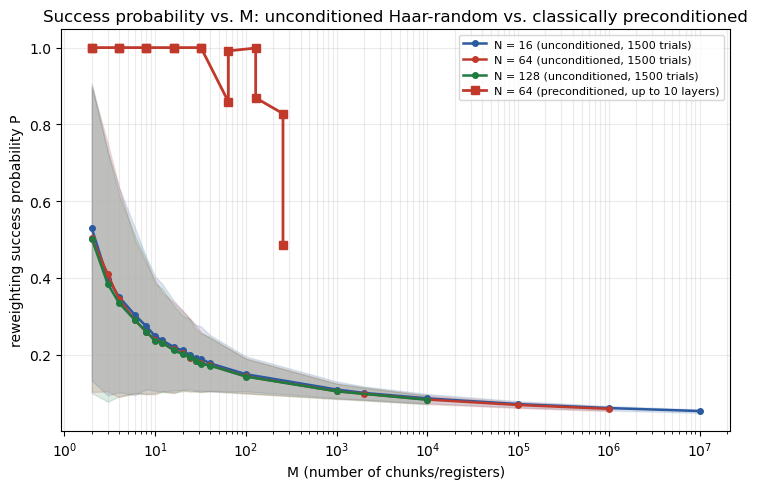

In [28]:
import numpy as np

fig, ax = plt.subplots(figsize=(7.5, 5))
for N, color in zip(N_values_1, LINE_COLORS):
    sub = df_M[df_M.N == N].sort_values("M")
    ax.plot(sub.M, sub.P_mean, color=color, marker='o', ms=4, lw=1.8, label=f"N = {N} (unconditioned, {N_TRIALS_1} trials)")
    ax.fill_between(sub.M, sub.P_p10, sub.P_p90, color=color, alpha=0.15)

precond_sorted = precond_df.sort_values("M")
ax.plot(precond_sorted["M"], precond_sorted["P_preconditioned"], color=RED, marker='s', ms=6, lw=2,
        label=f"N = {PRECOND_N} (preconditioned, up to {PRECOND_MAX_LAYERS} layers)")

ax.set_xscale("log")
ax.set_xlabel("M (number of chunks/registers)")
ax.set_ylabel("reweighting success probability P")
ax.set_title("Success probability vs. M: unconditioned Haar-random vs. classically preconditioned")
ax.legend(title="", fontsize=8)
ax.grid(alpha=0.25, which='both')
plt.tight_layout(); plt.savefig("sweep_P_vs_M_with_precond.png", dpi=130); plt.show()


In [27]:
PRECOND_N_LIST = [16, 64]
PRECOND_M_LIST = [2, 4, 8, 16, 32, 64, 128, 256]   # 512+ possible but will be slow, approaching R75-full qubit counts
PRECOND_MAX_LAYERS = 10
PRECOND_SAVE_PATH = "precond_vs_M.csv"

if os.path.exists(PRECOND_SAVE_PATH):
    precond_df = pd.read_csv(PRECOND_SAVE_PATH)
    done_MN = set(zip(precond_df["M"], precond_df["N"]))
else:
    precond_df = pd.DataFrame()
    done_MN = set()

rows_precond = precond_df.to_dict("records")
for N in PRECOND_N_LIST:
    for M in PRECOND_M_LIST:
        if (M, N) in done_MN:
            print(f"M={M}, N={N}: already done, skipping")
            continue
        n_qubits = int(round(np.log2(M * N)))
        if 2 ** n_qubits != M * N:
            print(f"M={M}, N={N}: M*N={M*N} is not a power of 2, skipping")
            continue

        t0 = time.time()
        rng_mn = np.random.default_rng(RNG_SEED + M * 100000 + N)
        raw = rng_mn.standard_normal((N, M)) + 1j * rng_mn.standard_normal((N, M))
        Y = raw / np.linalg.norm(raw)

        sigma0, chunks0 = extract_row_weights(Y)
        res_base = success_distribution(chunks0, sigma0, n_shots=3000, seed=RNG_SEED)

        v = Y.astype(np.complex128).T.flatten(); v /= np.linalg.norm(v)
        mps = qtn.MatrixProductState.from_dense(v.reshape([2] * n_qubits), dims=[2] * n_qubits)
        mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))

        seq = optimise_flatten_layers_hybrid(mps, PRECOND_MAX_LAYERS, seed=RNG_SEED, verbose=True)
        psi_final = seq["per_layer_psi"][-1]
        Y_final = psi_final.reshape(M, N).T
        sigmaF, chunksF = extract_row_weights(Y_final)
        res_final = success_distribution(chunksF, sigmaF, n_shots=3000, seed=RNG_SEED)

        row = {"M": M, "N": N, "n_qubits": n_qubits, "layers_used": seq["stopped_at"],
               "P_baseline": res_base["mean"], "P_preconditioned": res_final["mean"],
               "final_ipr": seq["per_layer_ipr"][-1], "time_s": time.time() - t0}
        rows_precond.append(row)
        pd.DataFrame(rows_precond).to_csv(PRECOND_SAVE_PATH, index=False)
        print(f"M={M:4d} N={N:3d} ({n_qubits} qubits): P {row['P_baseline']:.4f} -> {row['P_preconditioned']:.4f}  "
              f"({row['P_preconditioned']/row['P_baseline']:.1f}x)  {row['layers_used']} layers  "
              f"({row['time_s']:.1f}s)")

precond_df = pd.DataFrame(rows_precond)
print(f"\n{precond_df.to_string(index=False)}")


+0.031250000000 [best: +0.031250000000] :   2%|▏         | 3/200 [00:00<00:02, 77.98it/s] 


    layer 1/10: IPR 6.9312e-02 -> 3.1250e-02  stall=0


+0.031250000000 [best: +0.031250000000] :  20%|█▉        | 39/200 [00:00<00:03, 49.44it/s]


    layer 2/10: IPR 3.1250e-02 -> 3.1250e-02  stall=1


+0.031250000000 [best: +0.031250000000] :  18%|█▊        | 37/200 [00:00<00:03, 49.76it/s]


...

    layer 8/10: IPR 7.3622e-05 -> 7.2375e-05  stall=0


+0.000072178565 [best: +0.000072178565] : : 201it [00:12, 16.49it/s]                       
+0.000071208050 [best: +0.000071208050] : : 201it [01:54,  1.75it/s]                       


    layer 9/10: IPR 7.2375e-05 -> 7.1208e-05  stall=0


+0.000070975670 [best: +0.000070975670] : : 201it [00:13, 14.93it/s]                       
+0.000070056269 [best: +0.000070056269] : : 201it [01:21,  2.48it/s]                       


    layer 10/10: IPR 7.1208e-05 -> 7.0056e-05  stall=0
M= 256 N= 64 (14 qubits): P 0.1228 -> 0.4865  (4.0x)  10 layers  (635.7s)

  M  N  n_qubits  layers_used  P_baseline  P_preconditioned  final_ipr     time_s
  2 64         7            3    0.512544          0.999998   0.007813  21.925839
  4 64         8            5    0.340658          0.999993   0.003906  52.379811
  8 64         9            5    0.263418          0.999994   0.001953  40.511023
 16 64        10            5    0.214981          0.999982   0.000977  60.347194
 32 64        11            8    0.178313          0.999520   0.000488 166.836928
 64 64        12           10    0.145571          0.858923   0.000245 392.211099
  2 16         5            2    0.498031          1.000000   0.031250   3.288211
  4 16         6            2    0.376005          0.999998   0.015625  10.730233
  8 16         7            3    0.259232          0.999996   0.007813  50.384589
 16 16         8            3    0.153922         

## 6. Sweep 2: success probability vs. $N$ (fixed $M$)

In [30]:
rng_sweep2 = np.random.default_rng(RNG_SEED + 2)
N_grid = [2,4,8, 16, 32, 64, 128, 256, 512,2**10,2**11,2**12,2**13]
M_values_2 = [4, 10, 20]
N_TRIALS_2 = 1500

t0 = time.time()
rows_N = []
for M in M_values_2:
    print(f"M = {M}:")
    for N in N_grid:
        rows_N.append(run_trials_for_MN(M, N, N_TRIALS_2, rng_sweep2))
df_N = pd.DataFrame(rows_N)
print(f"\nsweep 2 done in {time.time()-t0:.1f}s, {len(df_N)} (M,N) points")
df_N.to_csv("sweep_success_prob_vs_N.csv", index=False)
df_N.head()

M = 4:
  M=  4 N=   2  (1500 trials, batch_size=500) done
  M=  4 N=   4  (1500 trials, batch_size=500) done
  M=  4 N=   8  (1500 trials, batch_size=500) done
  M=  4 N=  16  (1500 trials, batch_size=500) done
  M=  4 N=  32  (1500 trials, batch_size=500) done
  M=  4 N=  64  (1500 trials, batch_size=500) done
  M=  4 N= 128  (1500 trials, batch_size=500) done
  M=  4 N= 256  (1500 trials, batch_size=500) done
  M=  4 N= 512  (1500 trials, batch_size=500) done
  M=  4 N=1024  (1500 trials, batch_size=500) done
  M=  4 N=2048  (1500 trials, batch_size=381) done
  M=  4 N=4096  (1500 trials, batch_size=190) done
  M=  4 N=8192  (1500 trials, batch_size=95) done
M = 10:
  M= 10 N=   2  (1500 trials, batch_size=500) done
  M= 10 N=   4  (1500 trials, batch_size=500) done
  M= 10 N=   8  (1500 trials, batch_size=500) done
  M= 10 N=  16  (1500 trials, batch_size=500) done
  M= 10 N=  32  (1500 trials, batch_size=500) done
  M= 10 N=  64  (1500 trials, batch_size=500) done
  M= 10 N= 128  (

,M,N,P_n_trials,P_n_nonfinite,P_mean,P_median,P_p10,P_p90,P_min,P_max
0,4,2,1500,0,0.441455,0.440381,0.185540,0.685605,0.003768,0.917352
1,4,4,1500,0,0.384194,0.374046,0.128594,0.656446,0.000726,0.924941
2,4,8,1500,0,0.359125,0.339153,0.106470,0.641723,0.001398,0.919509
3,4,16,1500,0,0.341147,0.323608,0.096059,0.609845,0.000047,0.946822
4,4,32,1500,0,0.336705,0.313357,0.087876,0.619346,0.000047,0.933498


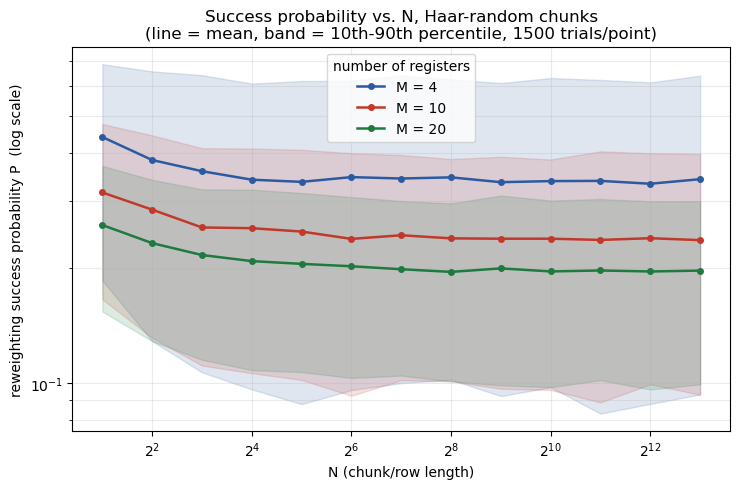

In [31]:
fig, ax = plt.subplots(figsize=(7.5, 5))
for M, color in zip(M_values_2, LINE_COLORS):
    sub = df_N[df_N.M == M].sort_values("N")
    ax.plot(sub.N, sub.P_mean, color=color, marker='o', ms=4, lw=1.8, label=f"M = {M}")
    ax.fill_between(sub.N, sub.P_p10, sub.P_p90, color=color, alpha=0.15)
ax.set_xscale('log', base=2)
ax.set_yscale('log')
ax.set_xlabel("N (chunk/row length)")
ax.set_ylabel("reweighting success probability P  (log scale)")
ax.set_title("Success probability vs. N, Haar-random chunks\n(line = mean, band = 10th-90th percentile, "
             f"{N_TRIALS_2} trials/point)")
ax.legend(title="number of registers")
ax.grid(alpha=0.25, which='both')
plt.tight_layout(); plt.savefig("sweep_P_vs_N.png", dpi=130); plt.show()

## 7. Sweep 3: 2D grid (heatmap)

In [11]:
rng_sweep3 = np.random.default_rng(RNG_SEED + 3)
M_grid_2d = [2, 4, 8, 12, 16, 20, 24, 28, 32]
N_grid_2d = [8, 16, 32, 64, 128, 256]
N_TRIALS_2D = 400

t0 = time.time()
rows_2d = []
for M in M_grid_2d:
    print(f"M = {M}:")
    for N in N_grid_2d:
        rows_2d.append(run_trials_for_MN(M, N, N_TRIALS_2D, rng_sweep3, verbose=False))
df_2d = pd.DataFrame(rows_2d)
print(f"2D sweep done in {time.time()-t0:.1f}s, {len(df_2d)} (M,N) points")
df_2d.to_csv("sweep_success_prob_2D.csv", index=False)

heat = df_2d.pivot(index="M", columns="N", values="P_mean").loc[M_grid_2d, N_grid_2d]
log_heat = np.log10(heat.values)

M = 2:
M = 4:
M = 8:
M = 12:


M = 16:
M = 20:


M = 24:


M = 28:


M = 32:


2D sweep done in 1.8s, 54 (M,N) points


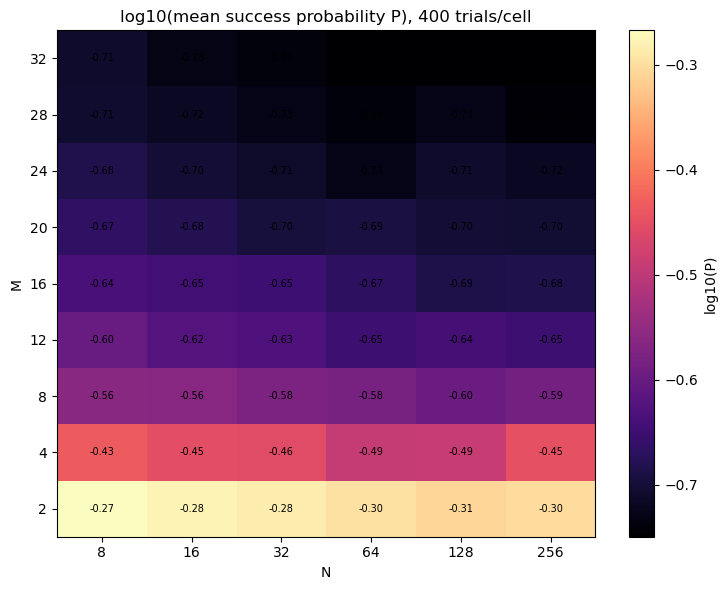

In [12]:
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(log_heat, aspect='auto', origin='lower', cmap='magma')
ax.set_xticks(range(len(N_grid_2d))); ax.set_xticklabels(N_grid_2d)
ax.set_yticks(range(len(M_grid_2d))); ax.set_yticklabels(M_grid_2d)
ax.set_xlabel("N"); ax.set_ylabel("M")
ax.set_title(f"log10(mean success probability P), {N_TRIALS_2D} trials/cell")
cb = fig.colorbar(im, ax=ax); cb.set_label("log10(P)")
for i in range(len(M_grid_2d)):
    for j in range(len(N_grid_2d)):
        ax.text(j, i, f"{log_heat[i,j]:.2f}", ha='center', va='center', fontsize=7,
                color='white' if log_heat[i, j] < log_heat.max() - 0.7 else 'black')
plt.tight_layout(); plt.savefig("sweep_P_heatmap.png", dpi=130); plt.show()

## 8. Sanity check against the theoretical per-branch decay $0.886^{M-1}$

This $0.886^{M-1}$ is a **different quantity** from $P=1/\beta^2$ (a per-branch tail
probability derived separately, not the true reweighting success probability) — so
this is only a shape/trend comparison, not a claim that the numbers should match.
Both curves are normalised to 1 at the smallest $M$ in the grid so their *decay
rates* (slopes on a log scale) can be compared directly.

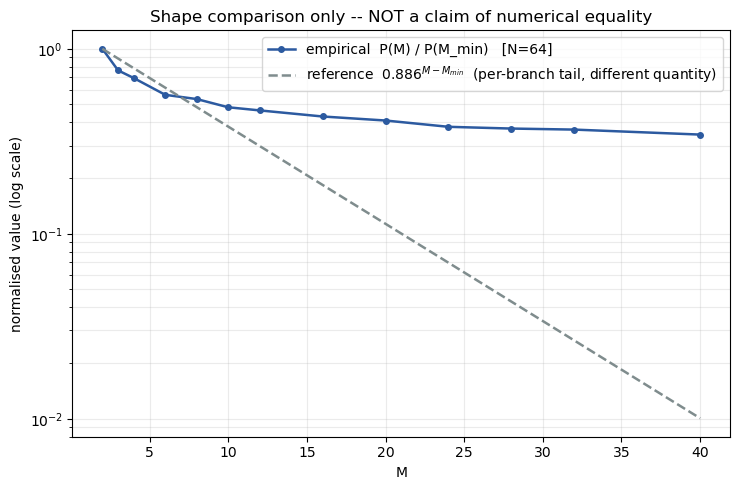

In [13]:
sub = df_M[df_M.N == 64].sort_values("M")
M_vals = sub.M.values
P_empirical = sub.P_mean.values
P_empirical_norm = P_empirical / P_empirical[0]

decay_rate = 0.886
P_theory = decay_rate ** (M_vals - M_vals[0])   # already 1 at M_vals[0]

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.plot(M_vals, P_empirical_norm, color=BLUE, marker='o', ms=4, lw=1.8,
        label="empirical  P(M) / P(M_min)   [N=64]")
ax.plot(M_vals, P_theory, color=GREY, ls='--', lw=1.8,
        label=r"reference  $0.886^{M-M_{min}}$  (per-branch tail, different quantity)")
ax.set_yscale('log')
ax.set_xlabel("M"); ax.set_ylabel("normalised value (log scale)")
ax.set_title("Shape comparison only -- NOT a claim of numerical equality")
ax.legend()
ax.grid(alpha=0.25, which='both')
plt.tight_layout(); plt.savefig("sweep_decay_comparison.png", dpi=130); plt.show()

## Summary / things to flag

- **Success probability is essentially flat in both $M$ and $N$ for Haar-random data.**
  $P$ drops from about 0.5 at $M=2$ to a plateau around 0.17-0.25 by $M\approx12$ and
  then stays roughly constant out to $M=40$ (see Sec. 5) — and it stays well-behaved
  (finite, in $[0,1]$) far beyond that grid, out to $M=1000$ in the validation checks
  in Sec. 3. It's similarly flat across $N=8\ldots512$ at fixed $M$ (Sec. 6). This was
  the main surprise going in — Haar random rows have tightly *concentrated* row norms
  (hence well-behaved $\sigma_i$) and Born-sampling preferentially picks
  large-amplitude components, so $\beta$ never blows up the way it does for the real,
  structured R75 data (where the same computation gave $P\approx0.005$, needing the
  IPR-flattening preconditioning step to become usable at all). **The takeaway: it
  isn't $M$ or $N$ in the abstract that hurts the success probability — it's
  structure/sparsity in the data.** Haar-random data is close to a best case for
  Stage 2; real, structured data is the hard case.
- **The $0.886^{M-1}$ reference decays far faster than the true $P$.** Over the same
  $M$ range where the per-branch reference would predict many orders of magnitude of
  decay, the true success probability barely moves past $M\approx12$. This confirms
  they're measuring different things, as expected, but it's a useful reminder that
  the per-branch tail bound is a poor proxy for the actual reweighting success
  probability on generic/random data — its relevance is presumably concentrated in
  the more adversarial (structured/sparse) regime instead.
- All raw per-$(M,N)$ summary statistics are saved to `sweep_success_prob_vs_M.csv`,
  `sweep_success_prob_vs_N.csv`, and `sweep_success_prob_2D.csv` for further analysis.